In [8]:
#Case Study 2: Delivery Time Optimization at a Courier Company

In [9]:
import numpy as np
from scipy.stats import t, ttest_1samp
import matplotlib.pyplot as plt


In [10]:
# Step 1: Simulate sample delivery times (in days)
np.random.seed(10)
delivery_times = np.random.normal(loc=2.4, scale=0.2, size=40)  # mean < 2.5 days



In [11]:
# Step 2: Perform one-tailed t-test
# H0: μ ≥ 2.5, H1: μ < 2.5
sample_mean = np.mean(delivery_times)
sample_std = np.std(delivery_times, ddof=1)
n = len(delivery_times)

t_stat = (sample_mean - 2.5) / (sample_std / np.sqrt(n))
p_value = t.cdf(t_stat, df=n-1)


In [12]:
# Output test results
print("Sample Mean:", round(sample_mean, 3))
print("Sample Std Dev:", round(sample_std, 3))
print("T-Statistic:", round(t_stat, 3))
print("P-value (one-tailed):", round(p_value, 4))

alpha = 0.05
if p_value < alpha:
    print(" Reject H₀: The new system significantly reduced delivery time.")
else:
    print(" Fail to reject H₀: Not enough evidence to support improvement.")


Sample Mean: 2.434
Sample Std Dev: 0.195
T-Statistic: -2.131
P-value (one-tailed): 0.0197
 Reject H₀: The new system significantly reduced delivery time.


In [13]:
# Step 3: 95% Confidence Interval for Mean
t_critical = t.ppf(1 - alpha/2, df=n-1)
margin_error = t_critical * sample_std / np.sqrt(n)
ci_lower = sample_mean - margin_error
ci_upper = sample_mean + margin_error

print(f"95% Confidence Interval: ({ci_lower:.3f}, {ci_upper:.3f})")


95% Confidence Interval: (2.372, 2.497)


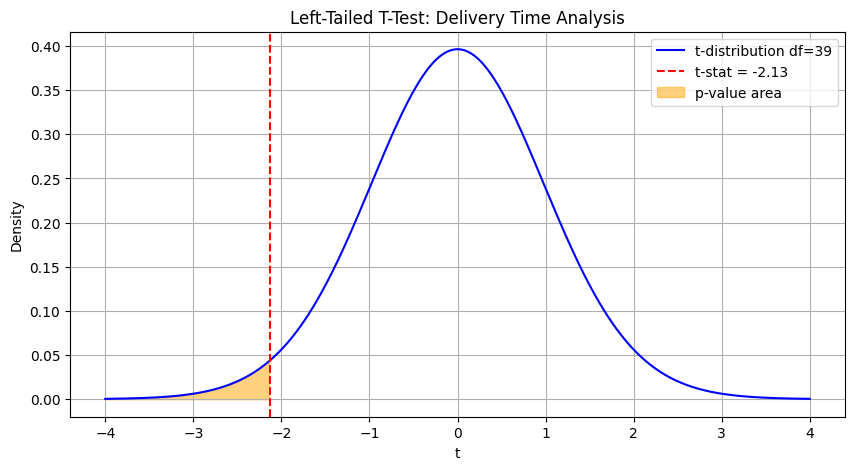

In [14]:
# Step 4: Plot t-distribution and p-value area
x = np.linspace(-4, 4, 500)
t_dist = t.pdf(x, df=n-1)

plt.figure(figsize=(10, 5))
plt.plot(x, t_dist, label='t-distribution df=39', color='blue')
plt.axvline(t_stat, color='red', linestyle='--', label=f't-stat = {t_stat:.2f}')
plt.fill_between(x, 0, t_dist, where=(x <= t_stat), color='orange', alpha=0.5, label='p-value area')
plt.title("Left-Tailed T-Test: Delivery Time Analysis")
plt.xlabel("t")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()
